# Visualisasi IMDI dan PMA Kabupaten/Kota 2022–2025


In [1]:
import os, sys, glob, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter
from scipy import stats

# ------------------------------------------------------------------ PENGATURAN
SHEET = 'Sheet 2'                       # sheet data bersih (format long, 2.056 baris)
SHOW = os.environ.get('SHOW', '1') != '0'   # False = hanya simpan file, tidak ditampilkan
DPI = 220
BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
OUT = BASE / 'figures'
OUT.mkdir(exist_ok=True)

def find_data():
    """Cari file .xlsx: argumen perintah > folder data/ > folder skrip."""
    if len(sys.argv) > 1 and sys.argv[1].lower().endswith('.xlsx') and Path(sys.argv[1]).exists():
        return Path(sys.argv[1])
    for pat in (BASE / 'data' / '*.xlsx', BASE / '*.xlsx'):
        hits = sorted(glob.glob(str(pat)))
        hits = [h for h in hits if not os.path.basename(h).startswith('~$')]
        if hits:
            return Path(hits[0])
    if 'google.colab' in sys.modules:                      # Google Colab: minta unggah file
        from google.colab import files
        name = list(files.upload().keys())[0]
        return Path(name)
    raise FileNotFoundError('File .xlsx tidak ditemukan. Taruh di folder data/ atau beri path sebagai argumen.')

DATA_FILE = find_data()
print('Data:', DATA_FILE)

# ------------------------------------------------------------------ GAYA GRAFIK
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['TeX Gyre Pagella', 'Palatino Linotype', 'Book Antiqua', 'Palatino', 'URW Palladio L', 'DejaVu Serif'],
    'font.size': 8, 'axes.titlesize': 8.5, 'axes.labelsize': 8, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'axes.unicode_minus': True,
})
NAVY, ORG, TEAL, PUR, GRY = '#1F3A5F', '#C8553D', '#2A9D8F', '#8C6BB1', '#6B6B6B'

def idn(x, d=1):
    """Format angka Indonesia: titik ribuan, koma desimal, tanda minus tipografis."""
    return f'{x:,.{d}f}'.replace(',', '#').replace('.', ',').replace('#', '.').replace('-', '−')

def finish(fig, name):
    fig.savefig(OUT / name, dpi=DPI, bbox_inches='tight', facecolor='white')
    print('  disimpan:', OUT / name)
    if SHOW:
        plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


Data: d:\imdi-pma-visualisasi\data\SherlyNatasyaZahwa_245020101111033.xlsx


## 1. Muat data dan cek cakupan sampel

In [2]:
df = pd.read_excel(DATA_FILE, sheet_name=SHEET)
df['pos'] = df.PMA_US_ribu > 0                      # wilayah-tahun dengan realisasi PMA positif
YEARS = sorted(df.tahun.unique())
m1 = df.dropna(subset=['lnPMA', 'IMDI']).copy()                                    # sampel Model 1
m2 = df.dropna(subset=['lnPMA', 'IMDI', 'lnPDRB', 'Pend', 'lnPMDN']).copy()        # sampel Model 2
print(f'Observasi total : {len(df):,} ({df.id.nunique()} kab/kota x {len(YEARS)} tahun)')
print(f'Model 1         : {len(m1):,} observasi, {m1.id.nunique()} kab/kota   (jurnal: 1.769 / 467)')
print(f'Model 2         : {len(m2):,} observasi, {m2.id.nunique()} kab/kota   (jurnal: 1.733 / 457)')
print(f'PMA positif     : {int(df.pos.sum()):,} ({df.pos.mean()*100:.1f}%)')

Observasi total : 2,056 (514 kab/kota x 4 tahun)
Model 1         : 1,769 observasi, 467 kab/kota   (jurnal: 1.769 / 467)
Model 2         : 1,733 observasi, 457 kab/kota   (jurnal: 1.733 / 457)
PMA positif     : 1,769 (86.0%)


## Tabel 1. Statistik deskriptif

In [3]:
def desc(s):
    return pd.Series({'N': s.count(), 'Rerata': s.mean(), 'Median': s.median(), 'Simpangan baku': s.std(),
                      'Minimum': s.min(), 'Maksimum': s.max()})
tabel1 = pd.DataFrame({
    'IMDI': desc(df.IMDI),
    'PMA (US$ juta)': desc(df.PMA_US_ribu[df.PMA_US_ribu > 0] / 1e3),
    'ln PMA': desc(df.lnPMA),
    'PDRB per kapita (Rp juta)': desc(df.PDRB_rp_ribu / 1e3),
    'ln PDRB per kapita': desc(df.lnPDRB),
    'Pend (tahun)': desc(df.Pend),
    'PMDN (Rp miliar)': desc(df.PMDN_rp_juta[df.PMDN_rp_juta > 0] / 1e3),
    'ln PMDN': desc(df.lnPMDN),
}).T
tabel1.round(2).to_csv(OUT / 'tabel1_statistik_deskriptif.csv', encoding='utf-8-sig')
print(tabel1.round(2).to_string())

                                N   Rerata  Median  Simpangan baku  Minimum  Maksimum
IMDI                       2056.0    42.60   43.14            6.66    16.50     64.77
PMA (US$ juta)             1769.0   119.66    6.77          498.20     0.00   7769.25
ln PMA                     1769.0    25.18   25.39            2.96    14.24     32.44
PDRB per kapita (Rp juta)  1952.0    71.26   49.00           86.78     7.03   1072.57
ln PDRB per kapita         1952.0    17.79   17.71            0.67    15.77     20.79
Pend (tahun)               2056.0     8.71    8.59            1.62     1.58     13.37
PMDN (Rp miliar)           2013.0  1526.09  332.03         4078.84     0.00  57560.34
ln PMDN                    2013.0    26.26   26.53            2.27    14.51     31.68


## Gambar 1. Tren rata-rata IMDI (dan empat pilar) serta total realisasi PMA

  disimpan: d:\imdi-pma-visualisasi\figures\gambar1_tren.png


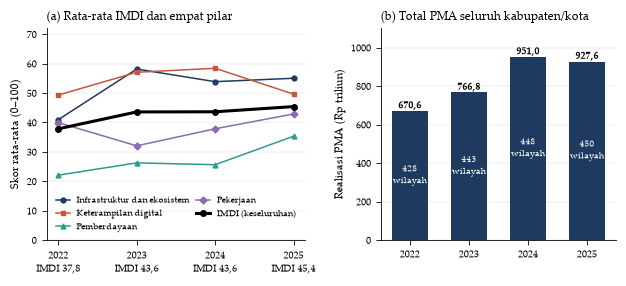

In [4]:
g = df.groupby('tahun')
imdi = g[['IMDI', 'Pilar_Infra', 'Pilar_Skill', 'Pilar_Berdaya', 'Pilar_Kerja']].mean()
total_pma = g.PMA_Rp.sum() / 1e12                   # Rp triliun
n_pos = g.pos.sum()

fig, ax = plt.subplots(1, 2, figsize=(6.3, 2.9), gridspec_kw={'width_ratios': [1.1, 1]})
a = ax[0]
for c, lab, col, mk in [('Pilar_Infra', 'Infrastruktur dan ekosistem', NAVY, 'o'),
                        ('Pilar_Skill', 'Keterampilan digital', ORG, 's'),
                        ('Pilar_Berdaya', 'Pemberdayaan', TEAL, '^'),
                        ('Pilar_Kerja', 'Pekerjaan', PUR, 'D')]:
    a.plot(YEARS, imdi[c], marker=mk, ms=3.5, lw=1.1, color=col, label=lab)
a.plot(YEARS, imdi.IMDI, color='black', lw=2.2, marker='o', ms=4, label='IMDI (keseluruhan)')
a.set_xticks(YEARS)
a.set_xticklabels([f'{y}\nIMDI {idn(v)}' for y, v in zip(YEARS, imdi.IMDI)], fontsize=7)
a.set_ylim(0, 72); a.set_ylabel('Skor rata-rata (0–100)')
a.set_title('(a) Rata-rata IMDI dan empat pilar', loc='left')
a.legend(fontsize=6.2, frameon=False, loc='lower center', ncol=2, columnspacing=0.8, handlelength=1.6)
a.grid(axis='y', lw=0.3, alpha=0.5)

b = ax[1]
b.bar(YEARS, total_pma, color=NAVY, width=0.62)
for x, y, n in zip(YEARS, total_pma, n_pos):
    b.text(x, y + 14, idn(y), ha='center', fontsize=7, fontweight='bold')
    b.text(x, y / 2, f'{int(n)}\nwilayah', ha='center', va='center', fontsize=6.3, color='white')
b.set_xticks(YEARS); b.set_ylim(0, 1100); b.set_ylabel('Realisasi PMA (Rp triliun)')
b.set_title('(b) Total PMA seluruh kabupaten/kota', loc='left')
b.grid(axis='y', lw=0.3, alpha=0.5); b.set_axisbelow(True)
fig.tight_layout(w_pad=1.5)
finish(fig, 'gambar1_tren.png')

## Gambar 2. Peluang dan besaran PMA menurut kuartil IMDI (kuartil dihitung per tahun)

           n    pos      med    imdi
kuartil                             
K1       516  0.734   52.233  37.020
K2       512  0.867   63.274  42.055
K3       513  0.901  114.892  44.880
K4       515  0.940  249.880  48.670
  disimpan: d:\imdi-pma-visualisasi\figures\gambar2_kuartil.png


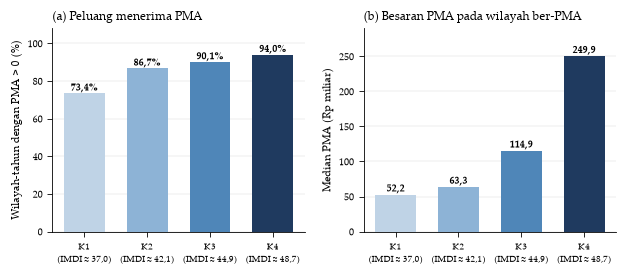

In [5]:
df['kuartil'] = df.groupby('tahun').IMDI.transform(lambda s: pd.qcut(s, 4, labels=['K1', 'K2', 'K3', 'K4']))
qt = df.groupby('kuartil', observed=True).agg(
    n=('id', 'size'),
    pos=('pos', 'mean'),
    med=('PMA_Rp', lambda s: s[s > 0].median() / 1e9),     # median PMA (Rp miliar), hanya wilayah ber-PMA
    imdi=('IMDI', 'median'))
print(qt.round(3).to_string())

shades = ['#BFD3E6', '#8DB3D6', '#4F86B8', NAVY]
labels = [f'K{i}\n(IMDI ≈ {idn(v)})' for i, v in zip(range(1, 5), qt.imdi)]
fig, ax = plt.subplots(1, 2, figsize=(6.3, 2.8))
a = ax[0]
a.bar(range(4), qt.pos * 100, color=shades, width=0.65)
for i, v in enumerate(qt.pos * 100):
    a.text(i, v + 1.5, idn(v) + '%', ha='center', fontsize=7.5, fontweight='bold')
a.set_ylim(0, 108); a.set_xticks(range(4)); a.set_xticklabels(labels, fontsize=6.6)
a.set_ylabel('Wilayah-tahun dengan PMA > 0 (%)'); a.set_title('(a) Peluang menerima PMA', loc='left')
b = ax[1]
b.bar(range(4), qt.med, color=shades, width=0.65)
for i, v in enumerate(qt.med):
    b.text(i, v + 5, idn(v), ha='center', fontsize=7.5, fontweight='bold')
b.set_ylim(0, 290); b.set_xticks(range(4)); b.set_xticklabels(labels, fontsize=6.6)
b.set_ylabel('Median PMA (Rp miliar)'); b.set_title('(b) Besaran PMA pada wilayah ber-PMA', loc='left')
for x in ax:
    x.grid(axis='y', lw=0.3, alpha=0.5); x.set_axisbelow(True)
fig.tight_layout(w_pad=1.5)
finish(fig, 'gambar2_kuartil.png')

## Gambar 3. Sepuluh kabupaten/kota dengan PMA kumulatif terbesar

10 wilayah teratas = 51.1% dari total PMA
25 wilayah teratas = 68.6% dari total PMA
50 wilayah teratas = 82.6% dari total PMA
  disimpan: d:\imdi-pma-visualisasi\figures\gambar3_top10.png


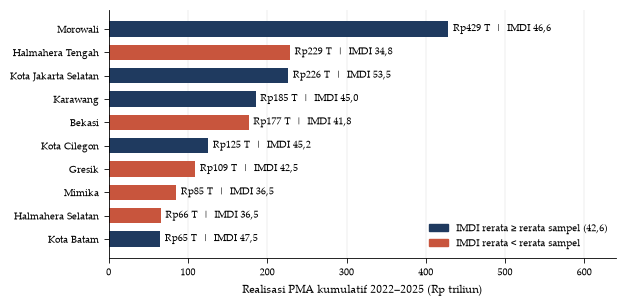

In [6]:
tot = (df.groupby(['id', 'Kabupaten_Kota'])
         .agg(PMA=('PMA_Rp', 'sum'), IMDI=('IMDI', 'mean')).reset_index()
         .sort_values('PMA', ascending=False))
top = tot.head(10).copy()
top['nama'] = top.Kabupaten_Kota.str.replace('B A T A M', 'BATAM', regex=False).str.title()
rerata_imdi = df.IMDI.mean()
for k in (10, 25, 50):
    print(f'{k} wilayah teratas = {tot.PMA.head(k).sum() / tot.PMA.sum() * 100:.1f}% dari total PMA')

fig, a = plt.subplots(figsize=(6.3, 3.1))
y = np.arange(10)[::-1]
a.barh(y, top.PMA / 1e12, color=[NAVY if v >= rerata_imdi else ORG for v in top.IMDI], height=0.66)
for yy, v, im in zip(y, top.PMA / 1e12, top.IMDI):
    a.text(v + 6, yy, f'Rp{idn(v, 0)} T  |  IMDI {idn(im)}', va='center', fontsize=7)
a.set_yticks(y); a.set_yticklabels(top.nama); a.set_xlim(0, 640)
a.set_xlabel('Realisasi PMA kumulatif 2022–2025 (Rp triliun)')
a.grid(axis='x', lw=0.3, alpha=0.5); a.set_axisbelow(True)
a.legend(handles=[Patch(color=NAVY, label=f'IMDI rerata ≥ rerata sampel ({idn(rerata_imdi)})'),
                  Patch(color=ORG, label='IMDI rerata < rerata sampel')], fontsize=7, frameon=False, loc='lower right')
fig.tight_layout()
finish(fig, 'gambar3_top10.png')

## Gambar 4. Diagram sebar IMDI vs ln PMA: gabungan dan dalam wilayah yang sama
Panel (b) mengurangkan rerata tiap kabupaten/kota (transformasi *within*), sehingga kemiringannya sama dengan koefisien efek tetap.

  disimpan: d:\imdi-pma-visualisasi\figures\gambar4_sebaran.png


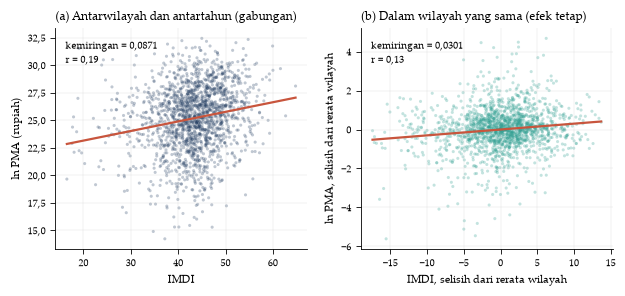

In [7]:
r_pool = np.corrcoef(m1.IMDI, m1.lnPMA)[0, 1]
b_pool = np.polyfit(m1.IMDI, m1.lnPMA, 1)
xw = m1.IMDI - m1.groupby('id').IMDI.transform('mean')
yw = m1.lnPMA - m1.groupby('id').lnPMA.transform('mean')
r_w = np.corrcoef(xw, yw)[0, 1]
b_w = np.polyfit(xw, yw, 1)

fig, ax = plt.subplots(1, 2, figsize=(6.3, 3.0))
a = ax[0]
a.scatter(m1.IMDI, m1.lnPMA, s=5, alpha=0.28, color=NAVY, edgecolor='none')
xs = np.linspace(m1.IMDI.min(), m1.IMDI.max(), 50)
a.plot(xs, b_pool[1] + b_pool[0] * xs, color=ORG, lw=1.6)
a.set_xlabel('IMDI'); a.set_ylabel('ln PMA (rupiah)')
a.yaxis.set_major_formatter(FuncFormatter(lambda v, p: idn(v, 1)))
a.set_title('(a) Antarwilayah dan antartahun (gabungan)', loc='left')
a.text(0.04, 0.95, f'kemiringan = {idn(b_pool[0], 4)}\nr = {idn(r_pool, 2)}', transform=a.transAxes, va='top', fontsize=7.5)
b = ax[1]
b.scatter(xw, yw, s=5, alpha=0.28, color=TEAL, edgecolor='none')
xs = np.linspace(xw.min(), xw.max(), 50)
b.plot(xs, b_w[1] + b_w[0] * xs, color=ORG, lw=1.6)
b.set_xlabel('IMDI, selisih dari rerata wilayah'); b.set_ylabel('ln PMA, selisih dari rerata wilayah')
b.set_title('(b) Dalam wilayah yang sama (efek tetap)', loc='left')
b.text(0.04, 0.95, f'kemiringan = {idn(b_w[0], 4)}\nr = {idn(r_w, 2)}', transform=b.transAxes, va='top', fontsize=7.5)
for x in ax:
    x.grid(lw=0.3, alpha=0.4)
fig.tight_layout(w_pad=1.5)
finish(fig, 'gambar4_sebaran.png')

## Gambar 5. Peta korelasi (heatmap), sampel Model 2

  disimpan: d:\imdi-pma-visualisasi\figures\gambar5_korelasi.png


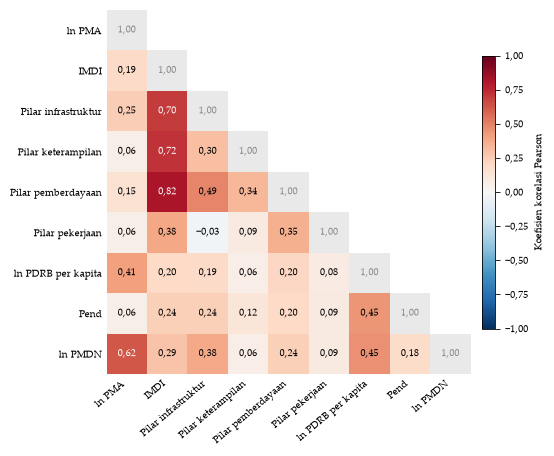

In [8]:
cols = ['lnPMA', 'IMDI', 'Pilar_Infra', 'Pilar_Skill', 'Pilar_Berdaya', 'Pilar_Kerja', 'lnPDRB', 'Pend', 'lnPMDN']
names = ['ln PMA', 'IMDI', 'Pilar infrastruktur', 'Pilar keterampilan', 'Pilar pemberdayaan', 'Pilar pekerjaan',
         'ln PDRB per kapita', 'Pend', 'ln PMDN']
C = m2[cols].corr().values
mask = np.triu(np.ones_like(C, dtype=bool), 0)

fig, a = plt.subplots(figsize=(6.3, 4.6))
im = a.imshow(np.ma.array(C, mask=mask), cmap='RdBu_r', vmin=-1, vmax=1)
for i in range(9):
    a.add_patch(Rectangle((i - .5, i - .5), 1, 1, color='#E9E9E9', lw=0))
    a.text(i, i, '1,00', ha='center', va='center', fontsize=7.3, color='#8A8A8A')
for i in range(9):
    for j in range(9):
        if not mask[i, j]:
            a.text(j, i, idn(C[i, j], 2), ha='center', va='center', fontsize=7.3,
                   color='white' if abs(C[i, j]) > 0.6 else 'black')
a.set_xticks(range(9)); a.set_yticks(range(9))
a.set_xticklabels(names, rotation=40, ha='right'); a.set_yticklabels(names)
a.spines[:].set_visible(False); a.tick_params(length=0)
cb = fig.colorbar(im, ax=a, shrink=0.75, pad=0.02)
cb.ax.tick_params(labelsize=7); cb.set_label('Koefisien korelasi Pearson', fontsize=7.5)
cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: idn(v, 2)))
fig.tight_layout()
finish(fig, 'gambar5_korelasi.png')

## Regresi untuk Gambar 6 dan Tabel 2
OLS (galat baku konvensional) dan efek tetap dengan galat baku robust klaster pada kabupaten/kota.
Koreksi sampel kecil dibuat setara dengan `xtreg ..., fe vce(cluster id)` pada Stata.

In [9]:
def ols(d, xs):
    X = np.column_stack([np.ones(len(d)), d[xs].values]); y = d.lnPMA.values
    b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b
    N, K = X.shape
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ X) * (e @ e) / (N - K)))
    tc = stats.t.ppf(0.975, N - K)
    return {n: (b[i + 1], se[i + 1], b[i + 1] - tc * se[i + 1], b[i + 1] + tc * se[i + 1]) for i, n in enumerate(xs)}

def fe_cluster(d, xs, year_fe=False):
    X0 = d[xs].copy()
    if year_fe:                                              # variabel boneka tahun (2022 = pembanding)
        for t in YEARS[1:]:
            X0[f'tahun{t}'] = (d.tahun == t).astype(float)
    names_ = list(X0.columns)
    Z = X0.copy(); Z['y'] = d.lnPMA.values; Z['id'] = d.id.values
    for c in names_ + ['y']:                                 # transformasi within
        Z[c] = Z[c] - Z.groupby('id')[c].transform('mean')
    X, y = Z[names_].values, Z['y'].values
    b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b
    G, N, K = d.id.nunique(), len(d), len(names_)
    XtXi = np.linalg.inv(X.T @ X); meat = np.zeros((K, K))
    for _, idx in Z.groupby('id').indices.items():
        s = X[idx].T @ e[idx]; meat += np.outer(s, s)
    V = XtXi @ meat @ XtXi * (G / (G - 1)) * ((N - 1) / (N - K - 1))   # K tidak menghitung konstanta, seperti Stata
    se = np.sqrt(np.diag(V)); tc = stats.t.ppf(0.975, G - 1)
    out = {n: (b[i], se[i], b[i] - tc * se[i], b[i] + tc * se[i], 2 * (1 - stats.t.cdf(abs(b[i] / se[i]), G - 1)))
           for i, n in enumerate(names_)}
    return out, 1 - (e @ e) / (y @ y), G, N      # R2 within

X2 = ['IMDI', 'lnPDRB', 'Pend', 'lnPMDN']
res = {
    'OLS, Model 1': ols(m1, ['IMDI'])['IMDI'],
    'FE robust, Model 1': fe_cluster(m1, ['IMDI'])[0]['IMDI'][:4],
    'OLS, Model 2': ols(m2, X2)['IMDI'],
    'FE robust, Model 2': fe_cluster(m2, X2)[0]['IMDI'][:4],
}
fe2y, r2w_y, G2, N2 = fe_cluster(m2, X2, year_fe=True)
fe1y = fe_cluster(m1, ['IMDI'], year_fe=True)[0]
res['FE robust + efek tahun, Model 2'] = fe2y['IMDI'][:4]

tabel2 = pd.DataFrame({k: dict(zip(['koefisien', 'galat_baku', 'CI95_bawah', 'CI95_atas'], v)) for k, v in res.items()}).T
tabel2.round(4).to_csv(OUT / 'tabel2_koefisien_IMDI.csv', encoding='utf-8-sig')
print(tabel2.round(4).to_string())
print(f"\nUji ketahanan (efek tahun): Model 1 IMDI = {fe1y['IMDI'][0]:.4f} (p = {fe1y['IMDI'][4]:.3f}); "
      f"Model 2 IMDI = {fe2y['IMDI'][0]:.4f} (p = {fe2y['IMDI'][4]:.3f}); R2 within = {r2w_y:.4f}")

                                 koefisien  galat_baku  CI95_bawah  CI95_atas
OLS, Model 1                        0.0871      0.0107      0.0661     0.1081
FE robust, Model 1                  0.0301      0.0067      0.0169     0.0432
OLS, Model 2                        0.0142      0.0089     -0.0034     0.0317
FE robust, Model 2                  0.0160      0.0081      0.0001     0.0319
FE robust + efek tahun, Model 2     0.0078      0.0084     -0.0088     0.0244

Uji ketahanan (efek tahun): Model 1 IMDI = 0.0093 (p = 0.261); Model 2 IMDI = 0.0078 (p = 0.357); R2 within = 0.0469


## Gambar 6. Koefisien IMDI pada lima spesifikasi

  disimpan: d:\imdi-pma-visualisasi\figures\gambar6_koefisien.png


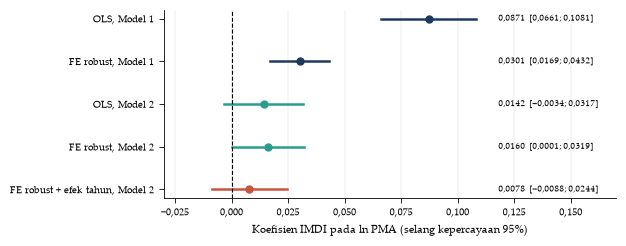

In [10]:
warna = [NAVY, NAVY, TEAL, TEAL, ORG]
fig, a = plt.subplots(figsize=(6.3, 2.5))
yy = np.arange(len(res))[::-1]
for y_, (lab, (b_, se_, lo, hi)), col in zip(yy, res.items(), warna):
    a.plot([lo, hi], [y_, y_], color=col, lw=1.8)
    a.plot([b_], [y_], 'o', color=col, ms=5)
    a.text(0.118, y_, f'{idn(b_, 4)}  [{idn(lo, 4)}; {idn(hi, 4)}]', va='center', fontsize=6.8)
a.axvline(0, color='black', lw=0.8, ls='--')
a.set_yticks(yy); a.set_yticklabels(list(res.keys())); a.set_xlim(-0.03, 0.17)
a.set_xlabel('Koefisien IMDI pada ln PMA (selang kepercayaan 95%)')
a.xaxis.set_major_formatter(FuncFormatter(lambda v, p: idn(v, 3)))
a.grid(axis='x', lw=0.3, alpha=0.5)
fig.tight_layout()
finish(fig, 'gambar6_koefisien.png')

## Pengecekan terhadap hasil Stata (jurnal)
Koefisien dan galat baku harus sama dengan output Stata pada laporan ekonometrika (selisih pembulatan < 0,0001).

In [11]:
stata = {   # (koefisien, galat baku) dari output Stata
    'OLS, Model 1': (0.0871012, 0.010701), 'FE robust, Model 1': (0.030058, 0.0066723),
    'OLS, Model 2': (0.014172, 0.0089477), 'FE robust, Model 2': (0.0160067, 0.0080972),
}
ok = True
for k, (b_s, se_s) in stata.items():
    b_p, se_p = res[k][0], res[k][1]
    cocok = abs(b_p - b_s) < 1e-4 and abs(se_p - se_s) < 1e-4
    ok &= cocok
    print(f'{k:22s} Python {b_p:.4f} ({se_p:.4f})  |  Stata {b_s:.4f} ({se_s:.4f})  ->  {"OK" if cocok else "BEDA"}')
print('\nSemua koefisien cocok dengan Stata.' if ok else '\nAda selisih dengan Stata, periksa file data.')
print('Selesai. Gambar tersimpan di:', OUT)

OLS, Model 1           Python 0.0871 (0.0107)  |  Stata 0.0871 (0.0107)  ->  OK
FE robust, Model 1     Python 0.0301 (0.0067)  |  Stata 0.0301 (0.0067)  ->  OK
OLS, Model 2           Python 0.0142 (0.0089)  |  Stata 0.0142 (0.0089)  ->  OK
FE robust, Model 2     Python 0.0160 (0.0081)  |  Stata 0.0160 (0.0081)  ->  OK

Semua koefisien cocok dengan Stata.
Selesai. Gambar tersimpan di: d:\imdi-pma-visualisasi\figures
